# 99 — Comparison: the whole v1 → v7 story

Two curves on one set of folds: what each version **as shipped** scores, and what the same version's feature/model stack scores **without class weights** (and with honest validation). The gap between them is the main finding of this project. Nothing is re-run here; it reads `results.jsonl`.

In [1]:
import sys, warnings, json
sys.path.insert(0, '.')
warnings.simplefilter('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from common import *
pd.set_option('display.width', 160); pd.set_option('display.max_colwidth', 60)
R = {(r['version'], r['label']): r for r in map(json.loads, RESULTS.read_text().splitlines())}
def row(v, prefix):
    hits = [r for (vv, l), r in R.items() if vv == v and l.startswith(prefix)]
    assert len(hits) == 1, (v, prefix, len(hits)); return hits[0]
SHIPPED = [('v1', 'A0'), ('v2', '+F'), ('v3', '3d'), ('v4', '4f'), ('v5', '5g'), ('v6', '6e'), ('v7', '7c blend')]
HONEST  = [('v1', 'A2'), ('v2', '+E'), ('v3', '3c'), ('v4', '4a'), ('v5', '5b'), ('v6', '6a'), ('v7', '7a blend')]
rows = []
for (v, s), (_, h) in zip(SHIPPED, HONEST):
    a, b = row(v, s), row(v, h)
    rows.append({'ver': v, 'shipped (as in repo)': a['mean'], 'shipped std': a['std'], 'no weights / honest': b['mean'], 'honest std': b['std'],
                 'gap': b['mean'] - a['mean']})
C = pd.DataFrame(rows).set_index('ver')
C.round(4)

,shipped (as in repo),shipped std,no weights / honest,honest std,gap
ver,,,,,
v1,0.8037,0.0045,0.8090,0.0034,0.0053
v2,0.7772,0.0034,0.7979,0.0038,0.0206
v3,0.7818,0.0044,0.8106,0.0047,0.0287
v4,0.7813,0.0031,0.8111,0.0034,0.0297
v5,0.7817,0.0047,0.8115,0.0036,0.0299
v6,0.7817,0.0056,0.8108,0.0039,0.0292
v7,0.7800,0.0066,0.8081,0.0046,0.0281


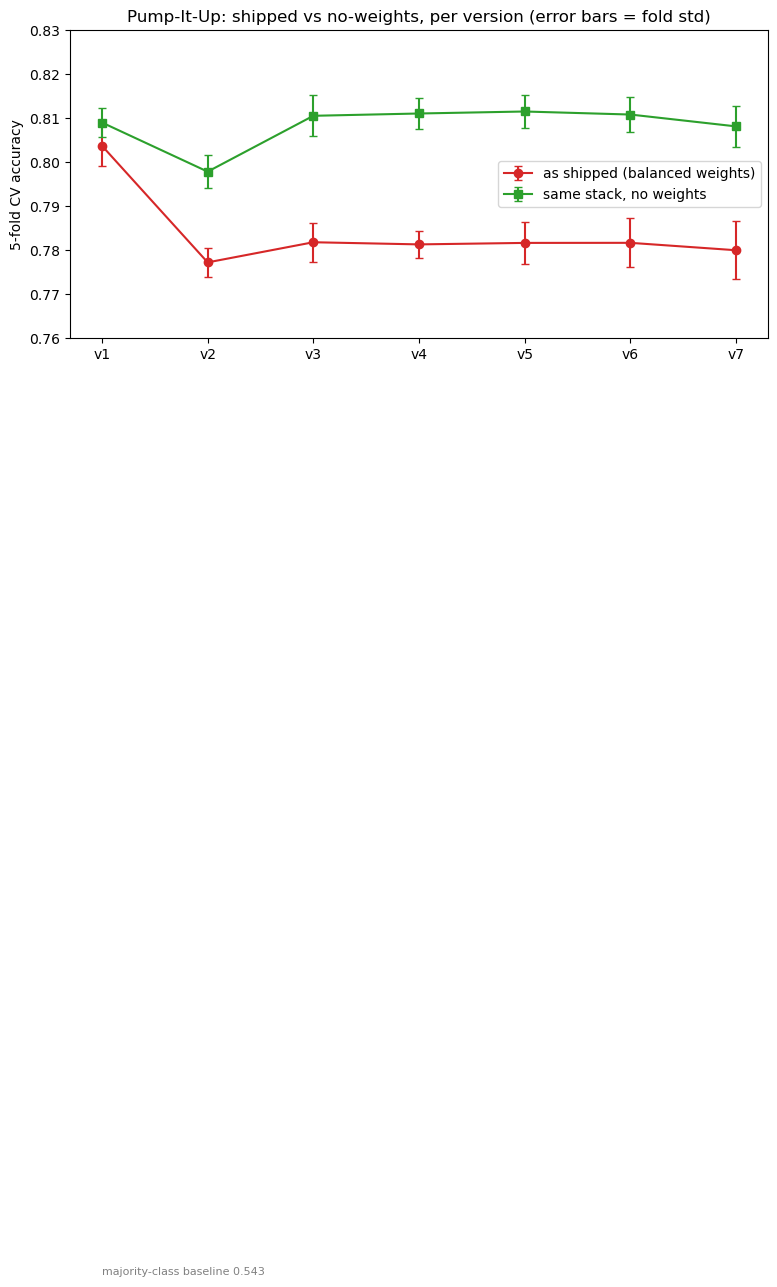

In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(C))
ax.errorbar(x, C['shipped (as in repo)'], yerr=C['shipped std'], fmt='o-', capsize=3, c='tab:red', label='as shipped (balanced weights)')
ax.errorbar(x, C['no weights / honest'], yerr=C['honest std'], fmt='s-', capsize=3, c='tab:green', label='same stack, no weights')
ax.axhline(0.5431, ls=':', c='gray'); ax.text(0, 0.5431 + .004, 'majority-class baseline 0.543', fontsize=8, color='gray')
ax.set_xticks(x); ax.set_xticklabels(C.index); ax.set_ylim(0.76, 0.83); ax.set_ylabel('5-fold CV accuracy'); ax.legend(loc='center right')
ax.set_title('Pump-It-Up: shipped vs no-weights, per version (error bars = fold std)')
plt.tight_layout(); plt.show()

## The progression that actually moved accuracy (same folds, no weights)

In [3]:
path = [('v1 as shipped protocol', 'v1', 'A0'), ('v1 leak-free', 'v1', 'A1'), ('v1 + drop MI cut', 'v1', 'A2'),
        ('v3 + searched params', 'v3', '3a'), ('v4 + geo_cluster', 'v4', '4a'), ('v5 + text collapse', 'v5', '5b'),
        ('v6 + interactions', 'v6', '6a'), ('v7 + LightGBM blend', 'v7', '7a blend')]
P = pd.DataFrame([{'step': n, 'acc': row(v, p)['mean'], 'std': row(v, p)['std']} for n, v, p in path])
P['Δ vs previous'] = P.acc.diff().round(4)
P['acc'] = P.acc.round(4); P['std'] = P['std'].round(4)
P.set_index('step')

,acc,std,Δ vs previous
step,,,
v1 as shipped protocol,0.8037,0.0045,NaN
v1 leak-free,0.8034,0.0044,-0.0003
v1 + drop MI cut,0.8090,0.0034,0.0056
v3 + searched params,0.8110,0.0038,0.0020
v4 + geo_cluster,0.8111,0.0034,0.0001
v5 + text collapse,0.8115,0.0036,0.0005
v6 + interactions,0.8108,0.0039,-0.0007
v7 + LightGBM blend,0.8081,0.0046,-0.0027


In [4]:
honest = [r for r in R.values() if 'val fold' not in r['label'] and 'as shipped' not in r['label'] and 'weights' not in r['label'].replace('no weights', '')]
b = max(honest, key=lambda r: r['mean']); print('best honest, no-weights row   :', b['version'], '|', b['label'], f"| {b['mean']:.4f} ± {b['std']:.4f}")

best honest, no-weights row   : v5 | 5e 5b + collapse ward, lga <20 (H8) | 0.8119 ± 0.0040


## Conclusion

**The repo's shipped versions all score about 0.78. The same stacks without class weights score about 0.81.**

| version | as shipped | same stack, no weights / honest | gap |
|---|---|---|---|
| v1 | 0.8037 | 0.8090 (no MI cut) | +0.005 *(no weights in v1; this is the MI cut)* |
| v2 | 0.7772 | 0.7979 | +0.021 |
| v3 | 0.7818 | 0.8106 | +0.029 |
| v4 | 0.7813 | 0.8111 | +0.030 |
| v5 | 0.7817 | 0.8115 | +0.030 |
| v6 | 0.7817 | 0.8108 | +0.029 |
| v7 | 0.7800 | 0.8081 | +0.028 |

- **Every shipped version from v2 on is worse than v1 (0.8037) on the competition metric**, and the shipped series is flat: v3 to v7 differ by < 0.002 even though each one added a feature or model. The weights set the score; the features did not.
- **Honest best ≈ 0.811–0.812** (v3's tuned params with any of v4/v5/v6 features), about **+0.008 over v1's untuned 0.803**, and +0.002 over v1 with its MI cut removed. After v3 the curve is flat within fold noise (std ≈ 0.004), and v7's blend sits *below* it (0.8081; 0.8105 with a deeper LightGBM).
- **Where the +0.008 came from:** removing the top-15 MI cut (+0.0056) and tuned params (~+0.002). Nothing else.

**What I would ship.** A single XGBoost with v3's searched params and the v5 feature set (`geo_cluster` and text cleaning are harmless, so keep or drop them), **no class weights**. Expected CV ≈ 0.811. The blend adds cost and risk for no measurable gain.

**What this analysis cannot tell you.**
1. **The leaderboard.** All numbers are local 5-fold CV on one seed. Random folds may be optimistic, because neighbouring pumps share traits. The first thing to do is submit the no-weights model to DrivenData and compare with its CV.
2. **The ordering of the noise-level changes.** Differences below ~0.004 can't be resolved with this setup. More seeds or repeated CV would be needed.
3. **Whether a different model class changes the story.** Everything here is depth-12 gradient-boosted trees. Interactions or text cleaning might matter for linear or shallow models.
4. **Whether class weights matter for another metric.** For macro-recall or recall on *needs repair*, the weights help (0.32 → 0.58). Here the metric is accuracy.

**Process lessons.** (1) Every version's write-up compared itself to the previous version's number, never to a leak-free, same-fold baseline; that is how weights went unnoticed for six versions. (2) A feature ranking high in gain importance (`quantity × waterpoint_type`, 1st of 45) told us nothing about whether it helped. (3) Reporting the ablation row by row, on fixed folds, is what made the real effects visible.